# F2 · 01 · Obtención y exploración inicial

**Qué hace este notebook:** descarga el dataset de LMArena, revisa su estructura real y describe cada variable por separado.
**Qué no hace:** comparar ganadores con perdedores ni sacar conclusiones sobre la pregunta P1 (eso es Fase 3).

Toda la lógica vive en `src/arena/`; acá solo se llama y se interpreta.

## 0. Entorno
**Qué hacemos:** registrar con qué versiones de Python y librerías corre el notebook.
**Por qué:** si algo falla en otro computador, lo primero que se compara son las versiones. Queda como evidencia de reproducibilidad.
**Qué esperamos:** Python 3.12 y las versiones de `requirements.txt`, con el intérprete dentro de `.venv`.

In [41]:
from arena.env import environment_info

info = environment_info()
{k: v for k, v in info.items() if k != "dependencies"}

{'python': '3.12.16',
 'system': 'Darwin 27.0.0',
 'interpreter': '/Users/alejandropoirier/Desktop/UNAB - Master/MCDI500/Semana 1/lmarena-sumativa1/.venv/bin/python',
 'virtual_env': True,
 'seed': 42,
 'git': {'branch': 'main', 'commit': '3c41aa4', 'clean': 'True'}}

### Dependencias: versión fijada vs. instalada

In [42]:
import pandas as pd

pd.DataFrame(info["dependencies"]).T

,pinned,installed,match
numpy,2.5.4,2.5.4,True
pandas,3.1.0,3.1.0,True
pyarrow,26.0.0,26.0.0,True
matplotlib,3.11.2,3.11.2,True
huggingface_hub,2.4.0,2.4.0,True
pytest,9.2.0,9.2.0,True
nbconvert,7.17.2,7.17.2,True
nbformat,5.11.1,5.11.1,True
ipykernel,7.4.0,7.4.0,True
jupyter_client,8.10.0,8.10.0,True


*Interpretación:* el notebook corre con Python 3.12 dentro del `.venv` del proyecto (`virtual_env: True`), con la semilla 42 declarada. La tabla compara, para cada dependencia, la versión fijada en `requirements.txt` con la instalada: todas coinciden (`match: True`). Además queda registrada la rama y el commit desde el que se ejecutó, que enlaza este resultado con el historial del repositorio.

## 1. Obtención
**Qué hacemos:** descargar el dataset desde Hugging Face a `data/raw/` y guardar la huella SHA-256 de cada archivo en `CHECKSUMS.txt`.
**Por qué:** la huella permite comprobar que todos los integrantes trabajan con exactamente el mismo dato, y detectar si un archivo se corrompe o cambia.
**Qué esperamos:** 7 archivos parquet de ~230 MB cada uno (~1,6 GB en total).

### 1.1 ¿Qué archivos hay en el repositorio remoto?

In [43]:
from arena.io import list_remote_files

list_remote_files()

['data/train-00000-of-00007.parquet',
 'data/train-00001-of-00007.parquet',
 'data/train-00002-of-00007.parquet',
 'data/train-00003-of-00007.parquet',
 'data/train-00004-of-00007.parquet',
 'data/train-00005-of-00007.parquet',
 'data/train-00006-of-00007.parquet']

*Interpretación:* el dataset viene dividido en 7 archivos parquet (`train-0000X-of-00007`), todos del mismo split `train`.

### 1.2 Descarga
Si un archivo ya está en `data/raw/`, no se vuelve a bajar. La primera vez puede tardar varios minutos.

In [44]:
from arena.io import download_dataset

paths = download_dataset()
len(paths)

7

*Interpretación:* quedaron los 7 archivos en `data/raw/data/`. Esa carpeta no se sube a git por su tamaño.

### 1.3 Huellas SHA-256
Calculamos la huella de cada archivo y la guardamos en `data/raw/CHECKSUMS.txt`, que sí se sube a git (los datos no).

In [45]:
from arena.io import write_checksums

write_checksums(paths)

PosixPath('/Users/alejandropoirier/Desktop/UNAB - Master/MCDI500/Semana 1/lmarena-sumativa1/data/raw/CHECKSUMS.txt')

*Interpretación:* `CHECKSUMS.txt` queda en el repositorio. Cualquier integrante puede comparar su descarga contra él.

### 1.4 Verificación
Volvemos a calcular las huellas y comparamos con las guardadas.

In [46]:
from arena.io import verify_checksums

verify_checksums()

{'data/train-00000-of-00007.parquet': True,
 'data/train-00001-of-00007.parquet': True,
 'data/train-00002-of-00007.parquet': True,
 'data/train-00003-of-00007.parquet': True,
 'data/train-00004-of-00007.parquet': True,
 'data/train-00005-of-00007.parquet': True,
 'data/train-00006-of-00007.parquet': True}

*Interpretación:* los 7 archivos coinciden con sus huellas (`True`): el dato descargado es íntegro.

## 2. Inspección estructural
**Qué hacemos:** mirar la forma del dato antes de tocarlo: columnas, tipos, cantidad de filas, nulos y valores distintos.
**Por qué:** nuestro esquema salió de la ficha de Hugging Face y de una muestra; acá lo confirmamos con el dato completo y anotamos las diferencias.
**Qué esperamos:** ~135.634 filas, 14 columnas, 7 archivos. Algunas columnas son estructuras anidadas.

### 2.1 Columnas y tipos (solo metadatos del archivo, no carga datos)

In [47]:
from arena.profile import raw_schema

raw_schema()

,column,arrow_type
0,id,string
1,model_a,string
2,model_b,string
3,winner,string
4,evaluation_session_id,string
5,evaluation_order,int32
6,conversation_a,"list<element: struct<role: string, content: li..."
7,conversation_b,"list<element: struct<role: string, content: li..."
8,full_conversation,list<element: struct<user: struct<role: string...
9,conv_metadata,"struct<sum_assistant_a_tokens: int32, header_c..."


*Interpretación:* son 14 columnas, como dice la ficha. Cinco son estructuras anidadas: `conversation_a`, `conversation_b`, `full_conversation` (texto de las conversaciones), `conv_metadata` y `category_tag`. Las otras nueve son simples (texto, enteros, booleano y fecha).

### 2.2 Filas por archivo

In [48]:
from arena.profile import count_rows

count_rows()

{'train-00000-of-00007.parquet': 19377,
 'train-00001-of-00007.parquet': 19377,
 'train-00002-of-00007.parquet': 19376,
 'train-00003-of-00007.parquet': 19376,
 'train-00004-of-00007.parquet': 19376,
 'train-00005-of-00007.parquet': 19376,
 'train-00006-of-00007.parquet': 19376,
 'total': 135634}

*Interpretación:* el total es 135.634 filas, repartidas casi por igual (19.376–19.377 por archivo). Coincide con la ficha.

### 2.3 Carga en memoria
Cargamos todo **menos** las tres columnas de texto de las conversaciones (`conversation_a`, `conversation_b`, `full_conversation`): pesan mucho y por licencia no las vamos a usar ni publicar. Más adelante sacaremos de ahí solo el largo del prompt.

In [49]:
from arena.profile import load_raw

df_raw = load_raw()
df_raw.shape

(135634, 11)

*Interpretación:* quedan 135.634 filas y 11 columnas. En memoria ocupa unos 115 MB, así que podemos trabajar con el dataset completo sin necesidad de muestrearlo.

### 2.4 Resumen por columna: tipo, nulos y valores distintos

In [50]:
from arena.profile import structure_summary

structure_summary(df_raw)

,column,dtype,nulls,null_pct,n_unique
0,id,str,0,0.0,135634
1,model_a,str,0,0.0,53
2,model_b,str,0,0.0,53
3,winner,str,0,0.0,4
4,evaluation_session_id,str,0,0.0,115372
5,evaluation_order,int32,0,0.0,28
6,conv_metadata,object,0,0.0,<NA>
7,category_tag,object,0,0.0,<NA>
8,language,str,0,0.0,126
9,is_code,bool,0,0.0,2


*Interpretación:*
- **Ninguna de las 11 columnas tiene nulos.** Esto cumple con el aviso del curso: lo declaramos en los supuestos.
- `id` es único (135.634 valores distintos), igual que `timestamp`.
- Hay 53 modelos distintos tanto en `model_a` como en `model_b`, y 126 idiomas.
- `winner` tiene 4 valores y `evaluation_order` llega a 28, como decía la ficha.
- `evaluation_session_id` tiene 115.372 valores distintos para 135.634 filas: hay sesiones con más de un voto.
- `conv_metadata` y `category_tag` no tienen conteo de distintos porque son diccionarios (no se pueden contar directamente).

## 3. Forma de las columnas anidadas
**Qué hacemos:** ver qué contiene `conv_metadata` y `category_tag` mirando una fila (solo nombres y tipos, no textos).
**Por qué:** definir cómo se aplanan en la limpieza (F2_02).
**Qué esperamos:** conteos de tokens, encabezados, listas y negritas por lado; y banderas booleanas de categoría.

### 3.1 `conv_metadata`

In [51]:
from arena.profile import nested_paths

nested_paths(df_raw["conv_metadata"].iloc[0])

{'sum_assistant_a_tokens': 'int',
 'header_count_a.h1': 'int',
 'header_count_a.h2': 'int',
 'header_count_a.h3': 'int',
 'header_count_a.h4': 'int',
 'header_count_a.h5': 'int',
 'header_count_a.h6': 'int',
 'list_count_a.ordered': 'int',
 'list_count_a.unordered': 'int',
 'bold_count_a.**': 'int',
 'bold_count_a.__': 'int',
 'context_a_tokens': 'int',
 'sum_assistant_b_tokens': 'int',
 'header_count_b.h1': 'int',
 'header_count_b.h2': 'int',
 'header_count_b.h3': 'int',
 'header_count_b.h4': 'int',
 'header_count_b.h5': 'int',
 'header_count_b.h6': 'int',
 'list_count_b.ordered': 'int',
 'list_count_b.unordered': 'int',
 'bold_count_b.**': 'int',
 'bold_count_b.__': 'int',
 'context_b_tokens': 'int',
 'sum_user_tokens': 'int',
 'turns': 'int'}

*Interpretación:* hay 26 valores numéricos por fila. Por cada lado (A y B): tokens de la respuesta (`sum_assistant_*_tokens`), tokens de contexto, encabezados contados por nivel (`h1` a `h6`), listas ordenadas y no ordenadas, y negritas con dos marcadores (`**` y `__`). Además hay dos valores comunes: `sum_user_tokens` y `turns`. **Esto difiere de nuestra suposición inicial:** no era un solo conteo de encabezados y de listas, sino uno por nivel o tipo. En la limpieza decidiremos si se suman.

### 3.2 `category_tag`

In [52]:
from arena.profile import nested_paths

nested_paths(df_raw["category_tag"].iloc[0])

{'creative_writing_v0.1.creative_writing': 'bool',
 'creative_writing_v0.1.score': 'str',
 'criteria_v0.1.complexity': 'bool',
 'criteria_v0.1.creativity': 'bool',
 'criteria_v0.1.domain_knowledge': 'bool',
 'criteria_v0.1.problem_solving': 'bool',
 'criteria_v0.1.real_world': 'bool',
 'criteria_v0.1.specificity': 'bool',
 'criteria_v0.1.technical_accuracy': 'bool',
 'if_v0.1.if': 'bool',
 'if_v0.1.score': 'int',
 'math_v0.1.math': 'bool'}

*Interpretación:* son 12 valores en 4 grupos: `creative_writing_v0.1` (bandera y puntaje de texto), `criteria_v0.1` (7 banderas: complejidad, creatividad, conocimiento de dominio, resolución de problemas, mundo real, especificidad y precisión técnica), `if_v0.1` (seguimiento de instrucciones: bandera y puntaje entero) y `math_v0.1` (bandera). Son etiquetas puestas por un sistema automático.

## 4. Variables nominales
**Qué hacemos:** contar cuántas veces aparece cada valor de `winner`, `language`, `is_code` y los modelos.
**Por qué:** conocer los desbalances antes de transformar.
**Qué esperamos:** inglés dominante y una parte no despreciable de empates.

### 4.1 `winner`

In [53]:
from arena.profile import frequency_table
from arena.plots import plot_bars

freq_winner = frequency_table(df_raw["winner"])
freq_winner

,count,pct
winner,,
model_b,49785,36.71
model_a,48563,35.80
tie,21532,15.88
both_bad,15754,11.62


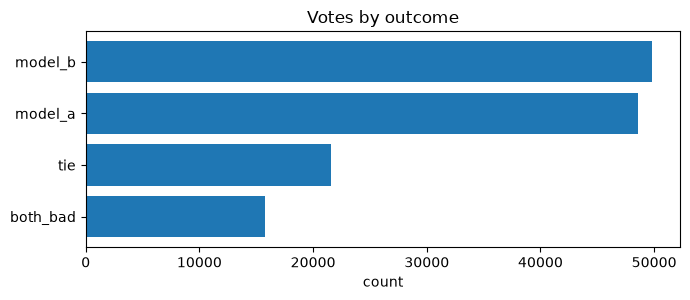

In [54]:
plot_bars(freq_winner, "Votes by outcome")

*Interpretación:* `model_b` (36,7 %) y `model_a` (35,8 %) están casi parejos. Los empates (`tie`, 15,9 %) y `both_bad` (11,6 %) suman el 27,5 % de los votos: más de una cuarta parte de las filas no tiene un lado ganador. **Hay que decidir cómo tratarlos en el análisis (F3).** La ficha no explica en qué se diferencian.

### 4.2 `language`

In [55]:
freq_lang = frequency_table(df_raw["language"], top=10)
freq_lang

,count,pct
language,,
en,71175,52.48
pl,13813,10.18
und,11835,8.73
ru,9263,6.83
zh,6501,4.79
de,4311,3.18
ko,2486,1.83
ja,2444,1.80
fr,2128,1.57


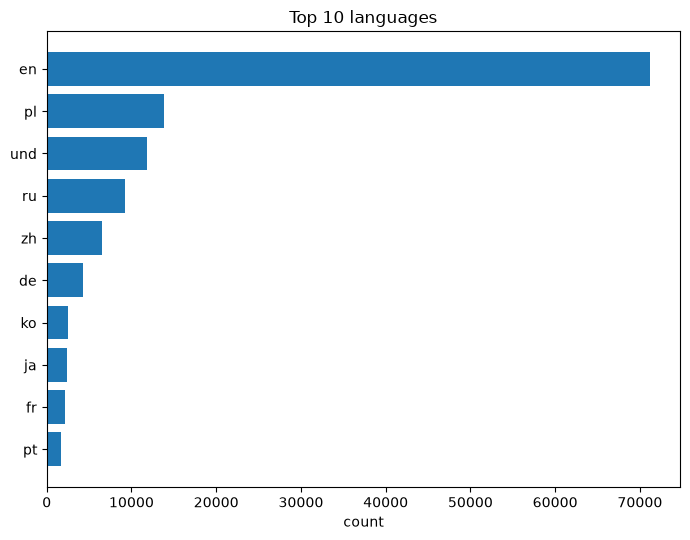

In [56]:
plot_bars(freq_lang, "Top 10 languages")

*Interpretación:* el inglés (`en`) es el 52,5 % del dataset, seguido de polaco (`pl`, 10,2 %). El tercer lugar es `und` (8,7 %), que significa idioma no determinado. Hay 126 idiomas en total, la mayoría con muy pocos casos. Como la longitud en tokens depende del idioma, en F3 probablemente conviene comparar dentro de un mismo idioma.

### 4.3 `is_code`

In [57]:
frequency_table(df_raw["is_code"])

,count,pct
is_code,,
False,96271,70.98
True,39363,29.02


*Interpretación:* el 29 % de los votos corresponde a prompts de código.

### 4.4 Modelos más frecuentes en el lado A

In [58]:
freq_model = frequency_table(df_raw["model_a"], top=10)
freq_model

,count,pct
model_a,,
claude-opus-4-20250514,4957,3.65
gemini-2.5-flash,4911,3.62
mistral-medium-2505,4599,3.39
gemini-2.5-pro,4576,3.37
qwen3-235b-a22b-no-thinking,4561,3.36
o3-2025-04-16,4272,3.15
claude-sonnet-4-20250514,4130,3.04
chatgpt-4o-latest-20250326,3816,2.81
gemma-3-27b-it,3675,2.71


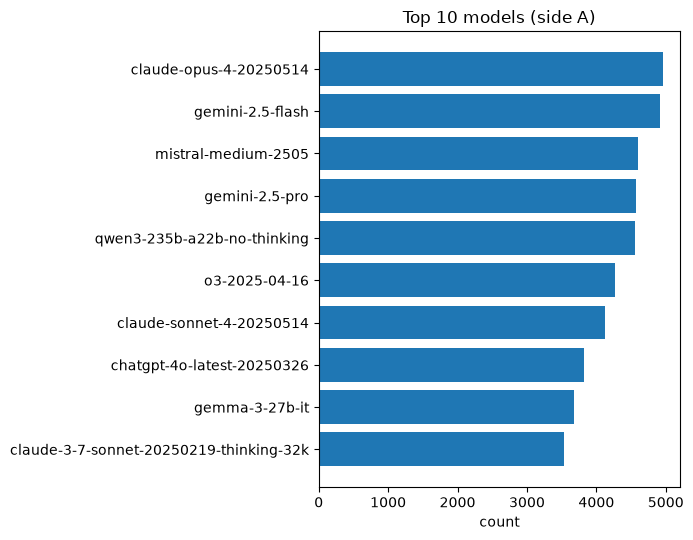

In [59]:
plot_bars(freq_model, "Top 10 models (side A)")

*Interpretación:* los 10 modelos más frecuentes aparecen entre ~3.500 y ~5.000 veces como lado A (2,6 % a 3,7 %), así que ningún modelo domina. Cuidado: acá solo contamos apariciones, no cuántas veces gana cada uno (eso es F3).

### 4.5 ¿Algún enfrentamiento de un modelo contra sí mismo?

In [60]:
(df_raw["model_a"] == df_raw["model_b"]).sum()

np.int64(10)

*Interpretación:* hay 10 filas donde `model_a` y `model_b` son el mismo modelo. Es un caso raro y probablemente un artefacto de la plataforma; lo revisaremos en la validación (F2_03).

## 5. Variables numéricas
**Qué hacemos:** describir `evaluation_order` y los conteos de tokens.
**Por qué:** detectar asimetría, ceros y valores extremos, que justificarán las transformaciones de F2_02.
**Qué esperamos:** distribuciones muy asimétricas.

### 5.1 `evaluation_order` (posición del voto dentro de la sesión)

In [61]:
frequency_table(df_raw["evaluation_order"]).sort_index().head(8)

,count,pct
evaluation_order,,
1,108315,79.86
2,15972,11.78
3,5350,3.94
4,2453,1.81
5,1310,0.97
6,744,0.55
7,495,0.36
8,304,0.22


*Interpretación:* el 79,9 % de los votos (108.315) es el primero de su sesión. La cola es larga: llega hasta 28, pero a partir del tercer voto quedan pocas filas. **Esto limita cualquier análisis que use el orden dentro de la sesión:** la mayoría de las sesiones aporta un solo voto, así que casi no hay datos para mirar cómo cambia algo a medida que la sesión avanza.

### 5.2 Tokens de las respuestas y del prompt

In [62]:
from arena.profile import nested_to_frame

meta = nested_to_frame(df_raw["conv_metadata"])
cols_tokens = ["sum_assistant_a_tokens", "sum_assistant_b_tokens", "sum_user_tokens"]
meta[cols_tokens].describe().round(1)

,sum_assistant_a_tokens,sum_assistant_b_tokens,sum_user_tokens
count,135634.0,135634.0,135634.0
mean,1149.8,1149.1,173.3
std,1716.2,1734.3,755.2
min,0.0,0.0,1.0
25%,322.0,318.0,16.0
50%,748.0,746.0,37.0
75%,1414.0,1417.0,101.0
max,88300.0,137128.0,54835.0


In [63]:
(meta[["sum_assistant_a_tokens", "sum_assistant_b_tokens"]] == 0).sum()

sum_assistant_a_tokens    61
sum_assistant_b_tokens    58
dtype: int64

*Interpretación:* la mediana de tokens de una respuesta es ~750, pero el promedio es ~1.150 y el máximo supera los 137.000: la distribución tiene una cola muy larga hacia la derecha. El prompt del usuario es mucho más corto (mediana de 37 tokens) y también muy asimétrico. Hay respuestas con 0 tokens (61 en el lado A y 58 en el B).

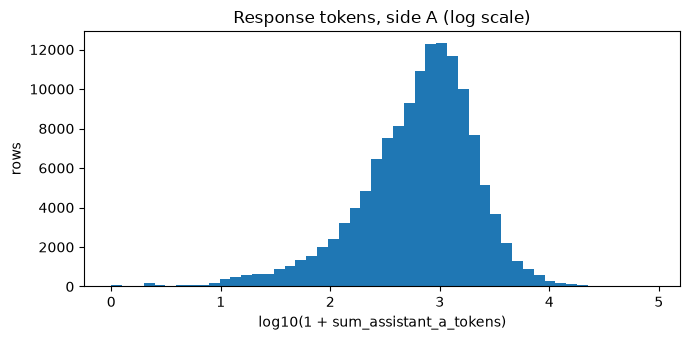

In [64]:
from arena.plots import plot_hist

plot_hist(meta["sum_assistant_a_tokens"], "Response tokens, side A (log scale)", log_x=True)

*Interpretación:* en escala logarítmica la forma se ve mucho más simétrica. Esto sugiere que trabajar con el logaritmo de los tokens (o con un escalamiento) tendrá sentido en la transformación.

## 6. Variable temporal
**Qué hacemos:** ver cuántos votos hay por día.
**Por qué:** detectar huecos o picos que sugieran problemas de recolección.

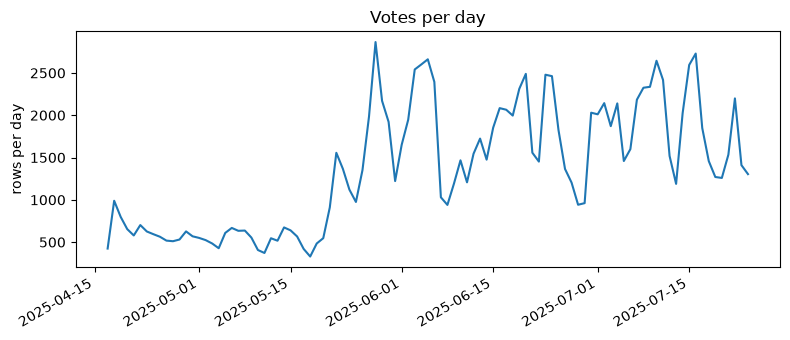

In [65]:
from arena.plots import plot_daily_counts

plot_daily_counts(df_raw["timestamp"], "Votes per day")

In [66]:
daily = df_raw["timestamp"].dt.floor("D").value_counts()
daily.describe()

count      99.000000
mean     1370.040404
std       729.926610
min       330.000000
25%       630.500000
50%      1351.000000
75%      2003.500000
max      2865.000000
Name: count, dtype: float64

In [67]:
df_raw["timestamp"].dt.to_period("M").value_counts().sort_index()

timestamp
2025-04     8686
2025-05    28033
2025-06    53447
2025-07    45468
Freq: M, Name: count, dtype: int64

*Interpretación:* los datos van del 17 de abril al 24 de julio de 2025 (99 días, ninguno vacío). La recolección no es pareja: abril es parcial (8.686 votos), mayo tiene 28.033, junio 53.447 y julio 45.468 (hasta el 24). Hay días de 330 votos y otros de 2.865. Por eso conviene no comparar meses entre sí sin cuidado.

## 7. Sesiones
**Qué hacemos:** contar cuántos votos tiene cada sesión.
**Por qué:** los votos de una misma sesión no son independientes, y eso importa para el muestreo y para F3.

In [68]:
sizes = df_raw.groupby("evaluation_session_id").size()
sizes.value_counts().sort_index().head(8)

1    102166
2      9404
3      2272
4       790
5       365
6       163
7        91
8        35
Name: count, dtype: int64

*Interpretación:* hay 115.372 sesiones. Casi 9 de cada 10 (88,6 %) tienen un solo voto; 13.206 sesiones (11,4 %) tienen más de uno, y la más larga llega a 25. Las filas no son independientes, así que cualquier análisis posterior debe considerar la sesión.

## 8. Muestreo
**Qué hacemos:** comparar dos formas de sacar una muestra del 10 %: por filas y por sesiones.
**Por qué:** no necesitamos muestrear para el análisis (el dataset cabe en memoria), pero sí puede servir una muestra chica para pruebas rápidas. Queremos ver cuál conserva la estructura.
**Qué esperamos:** el muestreo por filas parte las sesiones.

In [69]:
from arena.sampling import complete_session_share, sample_rows, sample_sessions

by_rows = sample_rows(df_raw, n=13_563, seed=42)
by_sessions = sample_sessions(df_raw, n_sessions=11_537, seed=42)

{
    "rows_sample": len(by_rows),
    "sessions_sample": len(by_sessions),
    "share_complete_by_rows": round(complete_session_share(by_rows, df_raw), 3),
    "share_complete_by_sessions": round(complete_session_share(by_sessions, df_raw), 3),
}

{'rows_sample': 13563,
 'sessions_sample': 13548,
 'share_complete_by_rows': 0.039,
 'share_complete_by_sessions': 1.0}

*Interpretación:* las dos muestras tienen un tamaño parecido (~13.500 filas, 10 % del dataset), pero no se comportan igual. Con el muestreo **por filas**, de las sesiones con más de un voto que aparecen en la muestra, solo el 3,9 % quedan completas: casi todas quedan partidas. Con el muestreo **por sesiones**, el 100 % queda completo, por construcción. Para pruebas rápidas conviene usar el muestreo por sesiones, y en F3 las pruebas y los intervalos tendrán que tratar la sesión como unidad. Para el análisis de esta entrega seguimos usando el dataset completo.

## 9. Resumen de hallazgos
Lo que encontramos y lo que pasa a la limpieza (F2_02) o a la validación (F2_03):

| # | Hallazgo | Qué hacer |
|---|---|---|
| 1 | Cero nulos en las 11 columnas cargadas | Declararlo en los supuestos; las columnas de texto no se revisaron |
| 2 | `conv_metadata` trae 26 conteos y `category_tag` 12 valores | Aplanar en F2_02 y decidir si se suman encabezados, listas y negritas |
| 3 | `winner`: 27,5 % son `tie` o `both_bad` | Crear variables derivadas; decidir su tratamiento en F3 (D-005) |
| 4 | 126 idiomas; 52,5 % inglés y 8,7 % `und` | Conservar `language`; decidir filtro en F3 (D-006) |
| 5 | Tokens muy asimétricos y con ceros (61 y 58) | Considerar escala logarítmica y revisar los ceros |
| 6 | 79,9 % de los votos son el primero de su sesión | Anotarlo como limitación: poca profundidad de sesión para mirar efectos de orden |
| 7 | Recolección despareja en el tiempo; abril parcial | Declararlo; no comparar meses sin cuidado |
| 8 | 11,4 % de las sesiones tienen más de un voto | Muestrear y analizar por sesión |
| 9 | Hay 10 filas con `model_a == model_b` | Revisar en la validación (F2_03) |

Con esto, F2_02 (limpieza y transformación) puede partir desde `load_raw()`.